In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold

from scikeras.wrappers import KerasRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.metrics import mean_absolute_error

2026-02-27 10:30:33.187623: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-27 10:30:33.196895: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772188233.207060  112566 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772188233.210334  112566 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772188233.218559  112566 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [3]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [4]:
# Fix random state
random_state = 42

In [5]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 95586 stars
galah contains 116050 stars
gr8 contains 1430 stars


In [6]:
apogee = apogee[apogee.parallax > 0.]
galah = galah[(galah.parallax > 0.) ]

apogee['rel_parallax'] = apogee.parallax_error / apogee.parallax
apogee = apogee[apogee.rel_parallax < 0.1]

galah['rel_parallax'] = galah.parallax_error / galah.parallax
galah = galah[galah.rel_parallax < 0.1]


harps['rel_parallax'] = harps.parallax_error / harps.parallax
harps = harps[harps.rel_parallax < 0.1]

# Seelcting only giants
apogee = apogee[apogee.logg < 3]

# Selecting only dwarfs
galah = galah[galah.logg > 3]


In [7]:
# Seelcting only giants
apogee = apogee[apogee.logg < 3]

# Selecting only dwarfs
galah = galah[galah.logg > 3]

In [8]:
print (f'harps contains {len(harps)} stars\n'
       f'apogee contains {len(apogee)} stars\n'
       f'galah contains {len(galah)} stars')

harps contains 798 stars
apogee contains 45812 stars
galah contains 71591 stars


In [9]:
galah.fe_h.describe()

count    71591.000000
mean        -0.048407
std          0.215807
min         -0.990000
25%         -0.180000
50%         -0.030000
75%          0.100000
max          0.590000
Name: fe_h, dtype: float64

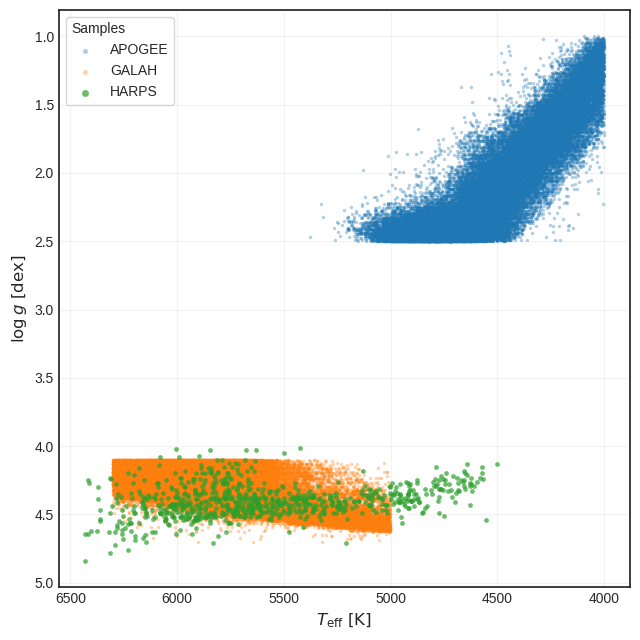

In [10]:
# Kiel diagram
import numpy as np
import matplotlib.pyplot as plt

def plot_kiel(
    harps_df, apogee_df, galah_df,
    teff_col="Teff", logg_col="logg",
    harps_label="HARPS", apogee_label="APOGEE", galah_label="GALAH",
    s_apogee=6, s_galah=6, s_harps=10, alpha_apogee=0.35, alpha_galah=0.35, alpha_harps=0.7
):
    """
    Make a spectroscopic HR (Kiel) diagram: logg vs Teff
    - logg increases downward
    - Teff increases to the left
    - HARPS points drawn on top

    DataFrames must have columns `teff_col` [K] and `logg_col` [dex].
    """

    def _xy(df):
        x = df[teff_col].to_numpy()
        y = df[logg_col].to_numpy()
        m = np.isfinite(x) & np.isfinite(y)
        return x[m], y[m]

    x_apo, y_apo   = _xy(apogee_df)
    x_gal, y_gal   = _xy(galah_df)
    x_harps, y_harps = _xy(harps_df)

    fig, ax = plt.subplots(figsize=(6.5, 6.5))

    # Dense surveys first (underlay)
    ax.scatter(x_apo,   y_apo,   s=s_apogee, alpha=alpha_apogee, label=apogee_label,
               linewidths=0, zorder=1, rasterized=True)
    ax.scatter(x_gal,   y_gal,   s=s_galah,  alpha=alpha_galah,  label=galah_label,
               linewidths=0, zorder=2, rasterized=True)

    # HARPS on top
    ax.scatter(x_harps, y_harps, s=s_harps,  alpha=alpha_harps,  label=harps_label,
               linewidths=0.2, zorder=3, rasterized=True)

    # Axes: Teff to the left, logg down
    ax.set_xlabel(r"$T_\mathrm{eff}\ \mathrm{[K]}$")
    ax.set_ylabel(r"$\log g\ \mathrm{[dex]}$")

    ax.invert_xaxis()  # Teff increases to the left
    ax.invert_yaxis()  # logg increases downward

    # Nice extras
    ax.grid(True, alpha=0.25)
    leg = ax.legend(frameon=True, title="Samples", markerscale=1.5)
    leg._legend_box.align = "left"

    # Tight layout for labels
    fig.tight_layout()
    return fig, ax

# Example usage (adjust column names if needed):
fig, ax = plot_kiel(harps, apogee, galah, teff_col="Teff", logg_col="logg")
# plt.show()


/tmp/ipykernel_112566/2696300626.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])


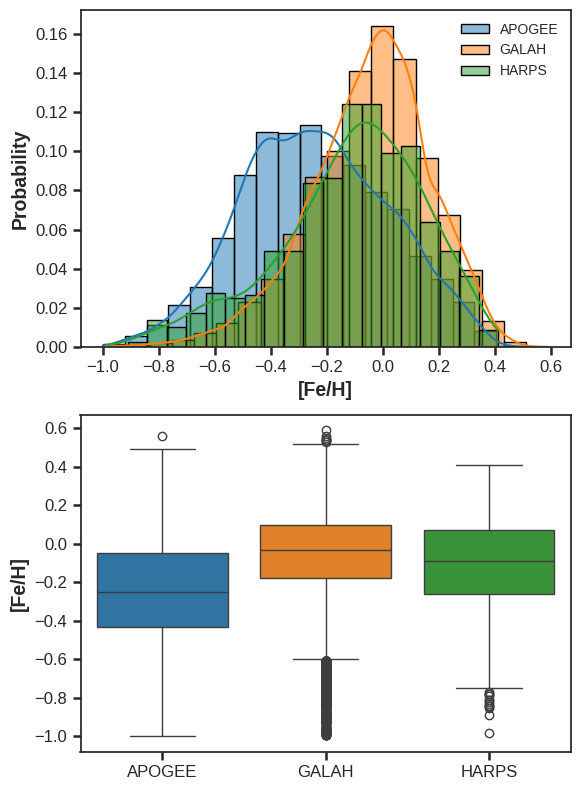

In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings

color_list = ["#1f77b4",  # blue
              "#ff7f0e",  # orange
              "#2ca02c"]  # green

cmap_custom = ListedColormap(color_list)

def plot_distribution_trio(
    df1, df2, df3, feature,
    labels=("df1", "df2", "df3"),
    hue="",
    palette=color_list,
    x_label_hist='[Fe/H]',          # new
    y_label_hist=None,          # new
    y_label_box='[Fe/H]'            # new
):
    # Add source labels
    df1_copy = df1.copy(); df1_copy[hue] = labels[0]
    df2_copy = df2.copy(); df2_copy[hue] = labels[1]
    df3_copy = df3.copy(); df3_copy[hue] = labels[2]

    # Concatenate all
    data_df = pd.concat([df1_copy, df2_copy, df3_copy], ignore_index=True)
    data_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    data_df = data_df[pd.to_numeric(data_df[feature], errors='coerce').notna()]
    data_df[feature] = data_df[feature].astype(float)

    # Begin plotting
    f, axes = plt.subplots(2, 1, figsize=(6, 8))

    # Histogram
    for i, s in enumerate(data_df[hue].unique()):
        selection = data_df.loc[data_df[hue] == s, feature]
        if len(selection) < 10:
            continue
        q_025, q_975 = np.percentile(selection, [0, 100])
        selection_filtered = selection[(selection >= q_025) & (selection <= q_975)]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=FutureWarning)
            sns.histplot(selection_filtered, bins = 20, color=palette[i], ax=axes[0], label=s, kde=True, stat='probability',)

    # Boxplot
    sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])

    # Titles
    #axes[0].set_title(f"[2.5%-97.5%] Distribution")
    #axes[1].set_title(f"Boxplot ")

    # Axis labels (apply if provided; else sensible defaults)
    axes[0].set_xlabel(x_label_hist if x_label_hist is not None else feature, fontsize=14)
    axes[0].set_ylabel(y_label_hist if y_label_hist is not None else "Probability", fontsize=14)
    axes[1].set_xlabel("")  # boxplot x label is usually redundant
    axes[1].set_ylabel(y_label_box if y_label_box is not None else feature, fontsize=14)

    # For the histogram axis
    axes[0].tick_params(axis='both', which='major', labelsize=12, length=6, width=1.8)
    axes[0].tick_params(axis='both', which='minor', labelsize=12, length=3, width=1.2)

    # For the boxplot axis
    axes[1].tick_params(axis='both', which='major', labelsize=12, length=6, width=1.8)
    axes[1].tick_params(axis='both', which='minor', labelsize=12, length=3, width=1.2)


    # Legend & layout
    axes[0].legend(title=hue)
    plt.tight_layout()
    plt.savefig(f'./figures/feh_dsitributiuons.png', dpi=300)
    plt.show()


plot_distribution_trio(apogee, galah, harps, feature='fe_h', labels=("APOGEE", "GALAH", "HARPS"))


/tmp/ipykernel_112566/3258764500.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])


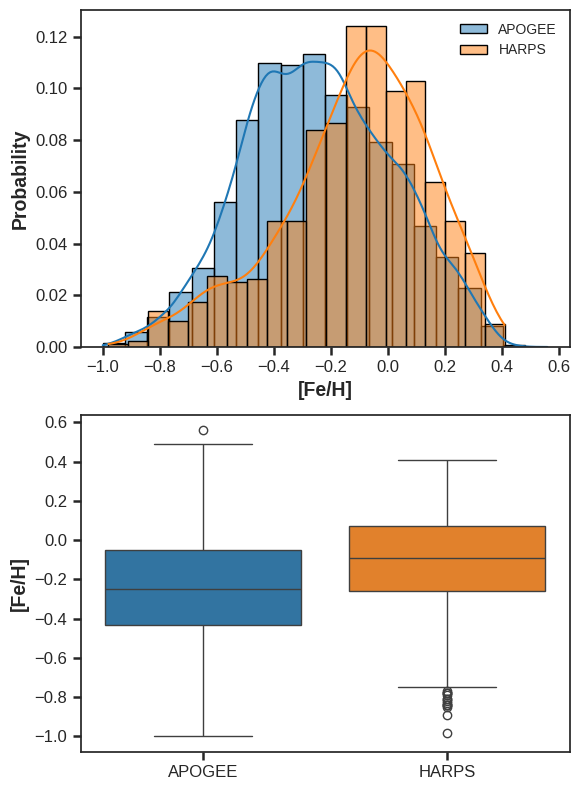

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# two colors only (APOGEE, HARPS)
color_list_2 = ["#1f77b4", "#ff7f0e"]  # blue, orange

def plot_distribution_duo(
    df1, df2, feature,
    labels=("df1", "df2"),
    hue="source",
    palette=color_list_2,
    x_label_hist='[Fe/H]',
    y_label_hist=None,
    y_label_box='[Fe/H]',
    bins=20,
    savepath="./figures/feh_distributions_apogee_harps.png",
    dpi=300
):
    # Add source labels
    df1_copy = df1.copy(); df1_copy[hue] = labels[0]
    df2_copy = df2.copy(); df2_copy[hue] = labels[1]

    # Concatenate
    data_df = pd.concat([df1_copy, df2_copy], ignore_index=True)

    # Clean
    data_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    data_df = data_df[pd.to_numeric(data_df[feature], errors='coerce').notna()]
    data_df[feature] = data_df[feature].astype(float)

    # Plot
    f, axes = plt.subplots(2, 1, figsize=(6, 8))

    # Histogram (per dataset)
    for i, s in enumerate(data_df[hue].unique()):
        selection = data_df.loc[data_df[hue] == s, feature]
        if len(selection) < 10:
            continue

        # you currently keep [0–100%]; leaving as-is (no trimming)
        q_025, q_975 = np.percentile(selection, [0, 100])
        selection_filtered = selection[(selection >= q_025) & (selection <= q_975)]

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=FutureWarning)
            sns.histplot(
                selection_filtered,
                bins=bins,
                color=palette[i],
                ax=axes[0],
                label=s,
                kde=True,
                stat='probability'
            )

    # Boxplot
    sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])

    # Axis labels
    axes[0].set_xlabel(x_label_hist if x_label_hist is not None else feature, fontsize=14)
    axes[0].set_ylabel(y_label_hist if y_label_hist is not None else "Probability", fontsize=14)
    axes[1].set_xlabel("")
    axes[1].set_ylabel(y_label_box if y_label_box is not None else feature, fontsize=14)

    # Tick styling
    axes[0].tick_params(axis='both', which='major', labelsize=12, length=6, width=1.8)
    axes[0].tick_params(axis='both', which='minor', labelsize=12, length=3, width=1.2)
    axes[1].tick_params(axis='both', which='major', labelsize=12, length=6, width=1.8)
    axes[1].tick_params(axis='both', which='minor', labelsize=12, length=3, width=1.2)

    # Legend & layout
    axes[0].legend(title=hue)
    plt.tight_layout()
    plt.savefig(savepath, dpi=dpi)
    plt.show()

# Call
plot_distribution_duo(
    apogee, harps,
    feature="fe_h",
    labels=("APOGEE", "HARPS"),
    hue=""
)

/tmp/ipykernel_112566/3258764500.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])


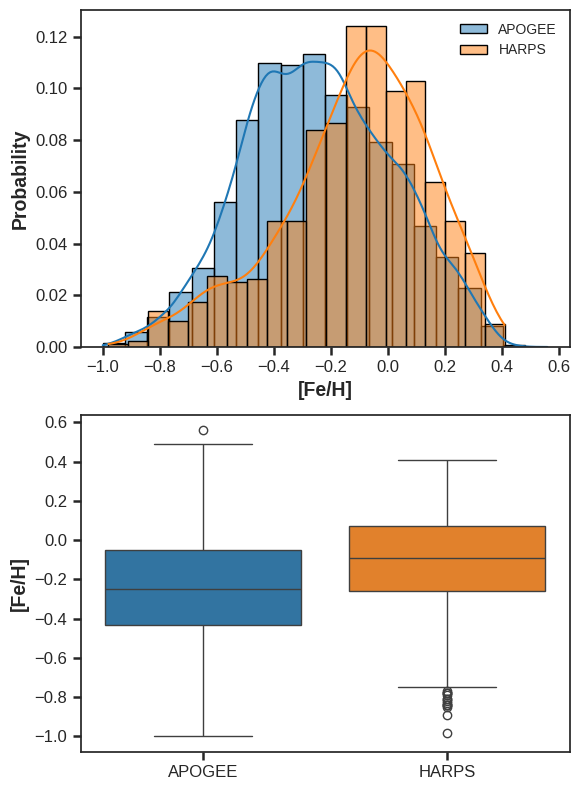

In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# two colors only (APOGEE, HARPS)
color_list_2 = ["#1f77b4", "#ff7f0e"]  # blue, orange

def plot_distribution_duo(
    df1, df2, feature,
    labels=("df1", "df2"),
    hue="source",
    palette=color_list_2,
    x_label_hist='[Fe/H]',
    y_label_hist=None,
    y_label_box='[Fe/H]',
    bins=20,
    savepath="./figures/feh_distributions_apogee_harps.png",
    dpi=300
):
    # Add source labels
    df1_copy = df1.copy(); df1_copy[hue] = labels[0]
    df2_copy = df2.copy(); df2_copy[hue] = labels[1]

    # Concatenate
    data_df = pd.concat([df1_copy, df2_copy], ignore_index=True)

    # Clean
    data_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    data_df = data_df[pd.to_numeric(data_df[feature], errors='coerce').notna()]
    data_df[feature] = data_df[feature].astype(float)

    # Plot
    f, axes = plt.subplots(2, 1, figsize=(6, 8))

    # Histogram (per dataset)
    for i, s in enumerate(data_df[hue].unique()):
        selection = data_df.loc[data_df[hue] == s, feature]
        if len(selection) < 10:
            continue

        # you currently keep [0–100%]; leaving as-is (no trimming)
        q_025, q_975 = np.percentile(selection, [0, 100])
        selection_filtered = selection[(selection >= q_025) & (selection <= q_975)]

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=FutureWarning)
            sns.histplot(
                selection_filtered,
                bins=bins,
                color=palette[i],
                ax=axes[0],
                label=s,
                kde=True,
                stat='probability'
            )

    # Boxplot
    sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])

    # Axis labels
    axes[0].set_xlabel(x_label_hist if x_label_hist is not None else feature, fontsize=14)
    axes[0].set_ylabel(y_label_hist if y_label_hist is not None else "Probability", fontsize=14)
    axes[1].set_xlabel("")
    axes[1].set_ylabel(y_label_box if y_label_box is not None else feature, fontsize=14)

    # Tick styling
    axes[0].tick_params(axis='both', which='major', labelsize=12, length=6, width=1.8)
    axes[0].tick_params(axis='both', which='minor', labelsize=12, length=3, width=1.2)
    axes[1].tick_params(axis='both', which='major', labelsize=12, length=6, width=1.8)
    axes[1].tick_params(axis='both', which='minor', labelsize=12, length=3, width=1.2)

    # Legend & layout
    axes[0].legend(title=hue)
    plt.tight_layout()
    plt.savefig(savepath, dpi=dpi)
    plt.show()

# Call
plot_distribution_duo(
    apogee, harps,
    feature="fe_h",
    labels=("APOGEE", "HARPS"),
    hue=""
)

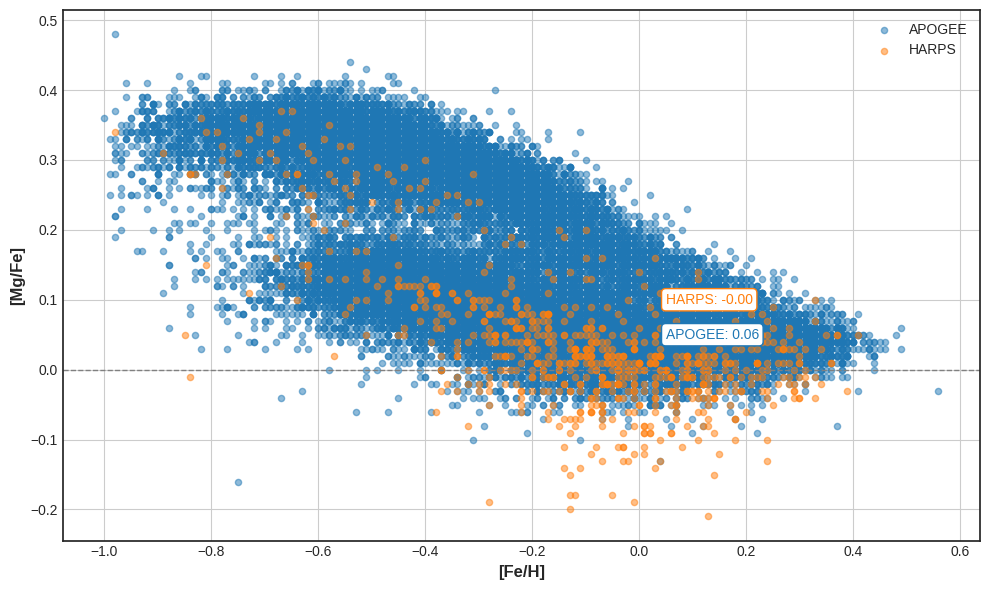

In [15]:
def plot_element_minus_feh_vs_feh(dfs, element='mg_h', labels=None, colors=None):
    """
    Plots [X/H] - [Fe/H] vs [Fe/H] for 2 or 3 DataFrames, with mean [X/Fe] in [-0.1, 0.1] annotated.

    Parameters:
        dfs: list of 2 or 3 pandas DataFrames
        element: string, element column name (e.g., 'mg_h')
        labels: list of labels (same length as dfs)
        colors: list of colors (same length as dfs)
    """
    if not (2 <= len(dfs) <= 3):
        raise ValueError("Please provide 2 or 3 DataFrames.")

    if labels is None:
        labels = [f'DF{i+1}' for i in range(len(dfs))]
    if len(labels) != len(dfs):
        raise ValueError("Length of 'labels' must match number of DataFrames.")

    if colors is None:
        default_colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
        colors = default_colors[:len(dfs)]

    fig, ax = plt.subplots(figsize=(10, 6))
    label_elem = element.split("_")[0].capitalize()
    y_offset = 0.05

    for i, (df, label, color) in enumerate(zip(dfs, labels, colors)):
        try:
            x = pd.to_numeric(df['fe_h'], errors='coerce')
            y = pd.to_numeric(df[element], errors='coerce')
            mask = x.notna() & y.notna()
            x = x[mask]
            y = y[mask]
            delta = y - x

            ax.scatter(x, delta, alpha=0.5, label=label, s=20, color=color)

            sel_mask = (x >= -0.1) & (x <= 0.1)
            if sel_mask.sum() >= 5:
                mean_val = delta[sel_mask].mean()
                ax.annotate(
                    f"{label}: {mean_val:.2f}",
                    xy=(0.05, 0.05 + i * y_offset),
                    xycoords='data',
                    color=color,
                    fontsize=10,
                    ha='left',
                    va='center',
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, lw=1)
                )
        except Exception as e:
            print(f"Skipping {label} due to error: {e}")

    ax.axhline(0, color='gray', linestyle='--', lw=1)
    ax.set_xlabel('[Fe/H]')
    ax.set_ylabel(f'[{label_elem}/Fe]')
    #ax.set_title(f'[{label_elem}/Fe] vs [Fe/H]')
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    plt.show()

plot_element_minus_feh_vs_feh(
    dfs=[apogee,  harps],
    element='mg_h',
    labels=[ 'APOGEE',  'HARPS']
)


In [16]:
harps.columns

Index(['Unnamed: 0', 'source_id', 'Star', 'ra', 'dec', 'parallax',
       'parallax_error', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error',
       'phot_g_mean_mag', 'phot_bp_mean_mag', 'phot_rp_mean_mag',
       'radial_velocity', 'radial_velocity_error', 'distance_gspphot', 'U_lsr',
       'V_lsr', 'W_lsr', 'P_gal', 'Teff', 'e_Teff', 'logg', 'e_logg', 'vtur',
       'e_vtur', 'fe_h', 'e_fe_h', 'mg_h', 'e_mg_h', 'si_h', 'e_si_h', 'c_h',
       'e_c_h', 'e_o_h', 'o_h', 'rapo', 'rperi', 'eccentricity', 'zmax', 'E',
       'ER', 'Ez', 'LcE', 'Lz', 'Op', 'Or', 'Oz', 'R', 'Tp', 'Tr', 'TrTp',
       'Tz', 'U', 'V', 'W', 'jp', 'jr', 'jz', 'rel_parallax'],
      dtype='object')

In [17]:
harps.fe_h.describe()

count    798.000000
mean      -0.114862
std        0.259546
min       -0.980000
25%       -0.260000
50%       -0.090000
75%        0.070000
max        0.410000
Name: fe_h, dtype: float64